In [14]:
from nltk.corpus import stopwords
# Importing the necessary libraries
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
stop_words = set(stopwords.words('english'))
import pandas as pd
import matplotlib.pyplot as plt


[nltk_data] Error loading punkt: <urlopen error [Errno 8] nodename nor
[nltk_data]     servname provided, or not known>
[nltk_data] Error loading punkt_tab: <urlopen error [Errno 8] nodename
[nltk_data]     nor servname provided, or not known>
[nltk_data] Error loading stopwords: <urlopen error [Errno 8] nodename
[nltk_data]     nor servname provided, or not known>


In [15]:
# load test dataset
test = pd.read_csv('data/jigsaw-toxic-comment-classification-challenge/test.csv', sep=',',header=0, na_values=[''], quotechar='"')

# cut a subset of the data for testing
test = test.sample(n=1000, random_state=42)

## Step 1: Single Texts

In [16]:
def count_nr_of_characters(text):
    return len(text)

def count_occurrences_of_a_character(text, character):
    return text.count(character)

def full_text_search_substring(text, substring):
    return text.find(substring)

def split_text_into_words(text):
    """Splits the text into words using nltk modules."""
    return nltk.word_tokenize(text)

def count_nr_of_words(text):
    """Counts the number of words with nltk modules."""
    words = nltk.word_tokenize(text)
    return len(words)

def count_occurrences_of_a_word(text, word):
    """Counts the number of occurrences of a word with nltk modules."""
    words = nltk.word_tokenize(text)
    return words.count(word)

def find_index_of_a_word(text, word):
    """Finds the index of a word with nltk modules."""
    words = nltk.word_tokenize(text)
    try:
        return words.index(word)
    except ValueError:
        return -1  # Return -1 if the word is not found


In [17]:
text = "Hello world! This is a sample text for NLP workbench. NLP is fun and useful."

print("Number of characters: ", count_nr_of_characters(text))
print("Occurrences of 'NLP': ", count_occurrences_of_a_character(text, 'NLP'))
print("Index of 'sample': ", full_text_search_substring(text, 'sample'))
print("Words in text: ", split_text_into_words(text))
print("Number of words: ", count_nr_of_words(text))
print("Occurrences of 'NLP': ", count_occurrences_of_a_word(text, 'NLP'))
print("Index of 'world': ", find_index_of_a_word(text, 'world'))

Number of characters:  76
Occurrences of 'NLP':  2
Index of 'sample':  23
Words in text:  ['Hello', 'world', '!', 'This', 'is', 'a', 'sample', 'text', 'for', 'NLP', 'workbench', '.', 'NLP', 'is', 'fun', 'and', 'useful', '.']
Number of words:  18
Occurrences of 'NLP':  2
Index of 'world':  1


## Step 2: Corpus Analysis

Next, extend your workbench to handle the entire corpus, with functionalities such as:
- Statistics of the entire corpus about number of files, text lengths, vocabulary etc.
- Good visualizations that help to “understand” the corpus easily
- Full text search on the entire corpus for single words (using an inverted index)

In [18]:
def count_nr_of_texts(corpus):
    """Nr of samples in df"""
    return len(corpus)

def sentence_lengths(corpus):
    """Returns a list of sentence lengths in the corpus."""
    lengths = []
    for text in corpus:
        sentences = nltk.sent_tokenize(text)
        lengths.extend([len(nltk.word_tokenize(sentence)) for sentence in sentences])
    return lengths

def vocabulary(corpus):
    """Returns a set of unique words in the corpus."""
    vocab = set()
    for text in corpus:
        words = nltk.word_tokenize(text)
        vocab.update(words)
    return vocab

def word_counts(corpus):
    """Returns a dictionary of word counts in the corpus."""
    word_count = {}
    for text in corpus:
        words = nltk.word_tokenize(text)
        for word in words:
            word_count[word] = word_count.get(word, 0) + 1
    return word_count

Mean sentence length: 18.253662109375
Max sentence length: 1000
Min sentence length: 1


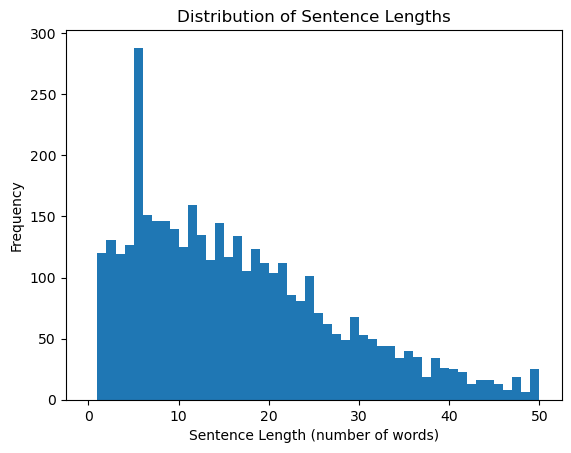

In [19]:
corpus = test['comment_text'].dropna().tolist()
lengths = sentence_lengths(corpus)

mean_sentence_length = sum(lengths) / len(lengths)
max_sentence_length = max(lengths)
min_sentence_length = min(lengths)
print(f"Mean sentence length: {mean_sentence_length}")
print(f"Max sentence length: {max_sentence_length}")
print(f"Min sentence length: {min_sentence_length}")

# Visualize the distribution of sentence lengths, cut x-axis at 50
plt.hist(lengths, bins=50, range=(0, 50))
plt.title('Distribution of Sentence Lengths')
plt.xlabel('Sentence Length (number of words)')
plt.ylabel('Frequency')
plt.show()

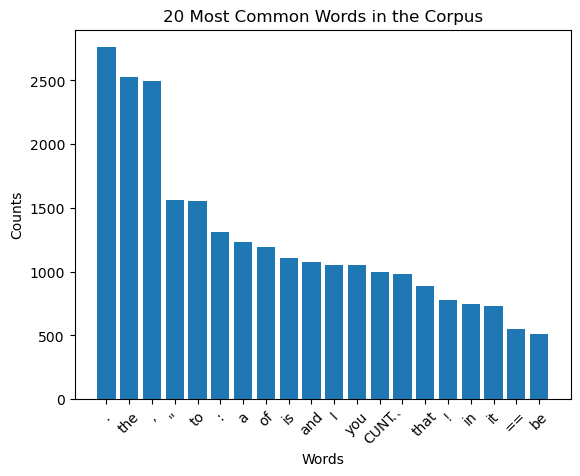

In [20]:
# create a bar chart of the 20 most common words in the corpus
word_count = word_counts(corpus)
most_common_words = sorted(word_count.items(), key=lambda x: x[1], reverse=True)[:20]
words, counts = zip(*most_common_words)
plt.bar(words, counts)
plt.title('20 Most Common Words in the Corpus')
plt.xlabel('Words')
plt.ylabel('Counts')
plt.xticks(rotation=45)
plt.show()


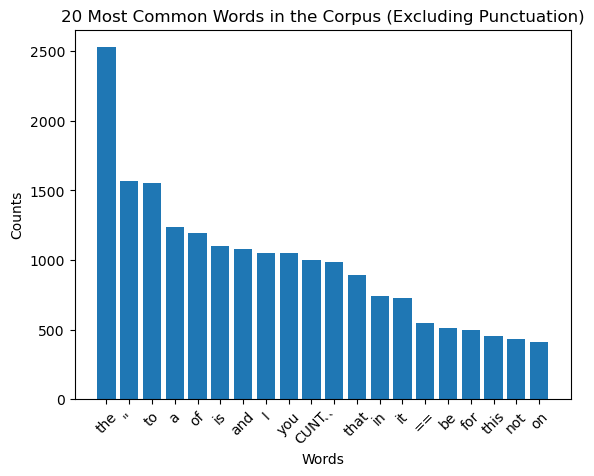

In [21]:
# create a bar chart of the 20 most common words in the corpus, exclude punctuation
import string
word_count = word_counts(corpus)
# Remove punctuation from the word count
for punct in string.punctuation:
    if punct in word_count:
        del word_count[punct]
most_common_words = sorted(word_count.items(), key=lambda x: x[1], reverse=True)[:20]
words, counts = zip(*most_common_words)
plt.bar(words, counts)
plt.title('20 Most Common Words in the Corpus (Excluding Punctuation)')
plt.xlabel('Words')
plt.ylabel('Counts')
plt.xticks(rotation=45)
plt.show()


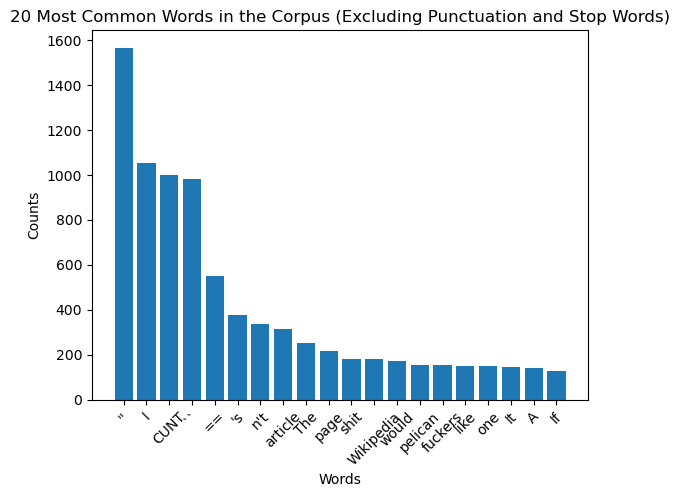

In [22]:
# create a bar chart of the 20 most common words in the corpus, exclude punctuation, remove stop words
word_count = word_counts(corpus)
# Remove punctuation and stop words from the word count
for punct in string.punctuation:
    if punct in word_count:
        del word_count[punct]
for stop_word in stop_words:
    if stop_word in word_count:
        del word_count[stop_word]
most_common_words = sorted(word_count.items(), key=lambda x: x[1], reverse=True)[:20]
words, counts = zip(*most_common_words)
plt.bar(words, counts)
plt.title('20 Most Common Words in the Corpus (Excluding Punctuation and Stop Words)')
plt.xlabel('Words')
plt.ylabel('Counts')
plt.xticks(rotation=45)
plt.show()